In [3]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torchinfo import summary 
import torch.optim as optim
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

In [4]:
import tables
import pandas as pd

N = 100_000

with tables.open_file("train.h5", mode="r") as h5:
    table = h5.root.table.table

    feature_names = list(table.attrs.values_block_0_kind)

    X_train = pd.DataFrame(
        table.read(
            field="values_block_0",
            start=0,
            stop=N
        )[:, :800],
        columns=feature_names[:800]
    )

    y_train = pd.Series(
        table.read(
            field="values_block_1",
            start=0,
            stop=N
        )[:, 1],
        name="is_signal_new"
    )

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print(y_train.value_counts())
display(X_train.head(20))
# display(y_train.head(50))

X_train: (100000, 800)
y_train: (100000,)
is_signal_new
1    50040
0    49960
Name: count, dtype: int64


,E_0,PX_0,PY_0,PZ_0,E_1,PX_1,PY_1,PZ_1,E_2,PX_2,...,PY_197,PZ_197,E_198,PX_198,PY_198,PZ_198,E_199,PX_199,PY_199,PZ_199
0,474.071136,-250.347031,-223.651962,-334.738098,103.236237,-48.866222,-56.790775,-71.025490,105.255569,-55.415001,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,150.504532,120.062393,76.852005,-48.274265,82.257057,63.801739,42.754807,-29.454842,48.573559,36.763199,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,251.645386,10.427651,-147.573746,203.564880,104.147797,10.718256,-54.497948,88.101395,78.043213,5.724113,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,451.566132,129.885437,-99.066292,-420.984100,208.410919,59.033958,-46.177090,-194.467941,190.183304,54.069675,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,399.093903,-168.432083,-47.205597,-358.717438,273.691956,-121.926941,-30.803854,-243.088928,152.837219,-44.400204,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,306.275299,96.237411,-27.163664,289.491028,283.876953,90.638680,-31.638950,267.151154,262.165558,83.561035,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,146.247421,66.247086,-42.599674,-123.227028,189.950287,58.527752,-45.889629,-174.784882,151.716171,45.033234,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,169.186386,-29.472824,86.933357,142.119583,83.599068,-11.078982,42.814793,70.943314,46.992054,-7.090906,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,142.818451,-80.388260,115.831711,22.756336,96.153008,-54.599506,77.578491,15.680322,88.052628,-49.205051,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,367.854797,142.678009,-15.802814,-338.689270,296.485931,114.453636,-11.433640,-273.264618,120.646027,49.435143,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
import numpy as np
import pandas as pd
import tables

def calculate_physics_features(h5_path, N=50_000, chunk_size=5_000):
    all_features = []
    all_labels = []

    with tables.open_file(h5_path, mode="r") as h5:
        table = h5.root.table.table
        n_rows = min(N, table.nrows)

        for start in range(0, n_rows, chunk_size):
            stop = min(start + chunk_size, n_rows)

            # Read constituent four-momenta only: 200 x (E, PX, PY, PZ)
            block = table.read(
                field="values_block_0",
                start=start,
                stop=stop
            )[:, :800]

            jets = block.reshape(-1, 200, 4).astype(np.float64)

            E  = jets[:, :, 0]
            px = jets[:, :, 1]
            py = jets[:, :, 2]
            pz = jets[:, :, 3]

            # Constituent-level observables
            pt = np.sqrt(px**2 + py**2)
            phi = np.arctan2(py, px)

            eta = np.zeros_like(pt)
            valid = pt > 1e-12
            eta[valid] = np.arcsinh(
                pz[valid] / pt[valid]
            )

            # Ignore zero-padded constituents
            active = (E != 0) | (pt != 0) | (pz != 0)
            pt_active = np.where(active, pt, 0.0)
            sum_pt = pt_active.sum(axis=1)

            # Total jet four-momentum
            E_jet = E.sum(axis=1)
            px_jet = px.sum(axis=1)
            py_jet = py.sum(axis=1)
            pz_jet = pz.sum(axis=1)

            pt_jet = np.sqrt(px_jet**2 + py_jet**2)
            p2_jet = px_jet**2 + py_jet**2 + pz_jet**2

            # Small negative values from numerical precision -> 0
            mass2 = E_jet**2 - p2_jet
            mass_jet = np.sqrt(np.maximum(mass2, 0.0))

            eta_jet = np.zeros_like(pt_jet)
            valid_jet = pt_jet > 1e-12
            eta_jet[valid_jet] = np.arcsinh(
                pz_jet[valid_jet] / pt_jet[valid_jet]
            )

            phi_jet = np.arctan2(py_jet, px_jet)
            multiplicity = active.sum(axis=1)

            # Angular distance from each constituent to the jet axis
            dphi = np.arctan2(
                np.sin(phi - phi_jet[:, None]),
                np.cos(phi - phi_jet[:, None])
            )
            deta = eta - eta_jet[:, None]
            delta_R = np.sqrt(deta**2 + dphi**2)

            # pT-weighted radial moment (jet girth)
            girth = np.divide(
                (pt_active * delta_R).sum(axis=1),
                sum_pt,
                out=np.zeros_like(sum_pt),
                where=sum_pt > 0
            )

            # pT dispersion
            pt_dispersion = np.sqrt(
                np.divide(
                    (pt_active**2).sum(axis=1),
                    sum_pt**2,
                    out=np.zeros_like(sum_pt),
                    where=sum_pt > 0
                )
            )

            # Approximate N-subjettiness, beta=1, R0=0.8.
            # tau1: jet axis; tau2: two leading-pT constituent axes.
            # This is a simple proxy, NOT a standard optimized tau21.
            R0 = 0.8
            tau1 = np.divide(
                (pt_active * delta_R).sum(axis=1),
                sum_pt * R0,
                out=np.zeros_like(sum_pt),
                where=sum_pt > 0
            )

            order = np.argsort(-pt_active, axis=1)
            rows = np.arange(len(jets))
            idx1 = order[:, 0]
            idx2 = order[:, 1]

            eta1, phi1 = eta[rows, idx1], phi[rows, idx1]
            eta2, phi2 = eta[rows, idx2], phi[rows, idx2]

            dr1 = np.sqrt(
                (eta - eta1[:, None])**2
                + np.arctan2(
                    np.sin(phi - phi1[:, None]),
                    np.cos(phi - phi1[:, None])
                )**2
            )
            dr2 = np.sqrt(
                (eta - eta2[:, None])**2
                + np.arctan2(
                    np.sin(phi - phi2[:, None]),
                    np.cos(phi - phi2[:, None])
                )**2
            )

            tau2 = np.divide(
                (pt_active * np.minimum(dr1, dr2)).sum(axis=1),
                sum_pt * R0,
                out=np.zeros_like(sum_pt),
                where=sum_pt > 0
            )

            tau21 = np.divide(
                tau2, tau1,
                out=np.zeros_like(tau2),
                where=tau1 > 1e-12
            )

            features = pd.DataFrame({
                "jet_mass": mass_jet,
                "jet_pt": pt_jet,
                "jet_eta": eta_jet,
                "jet_phi": phi_jet,
                "constituent_multiplicity": multiplicity,
                "jet_girth": girth,
                "pt_dispersion": pt_dispersion,
                "tau1_approx": tau1,
                "tau2_approx": tau2,
                "tau21_approx": tau21
            })

            # Read classification labels: 1 = top, 0 = QCD
            label_block = table.read(
                field="values_block_1",
                start=start,
                stop=stop
            )
            labels = label_block[:, 1]

            all_features.append(features)
            all_labels.append(labels)

    X = pd.concat(all_features, ignore_index=True)
    y = pd.Series(
        np.concatenate(all_labels),
        name="is_signal_new"
    )

    return X, y

In [7]:
X_train,y_train = calculate_physics_features('train.h5',N=100000)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print(y_train.value_counts())

display(X_train.head())
display(y_train.head())

X_train shape: (100000, 10)
y_train shape: (100000,)
is_signal_new
1    50040
0    49960
Name: count, dtype: int64


,jet_mass,jet_pt,jet_eta,jet_phi,constituent_multiplicity,jet_girth,pt_dispersion,tau1_approx,tau2_approx,tau21_approx
0,37.395616,617.077017,-0.874543,-2.400258,23,0.034444,0.573756,0.043055,0.013138,0.305135
1,46.999459,556.271305,-0.360226,0.578900,43,0.043689,0.331117,0.054611,0.039329,0.720165
2,61.650285,551.548764,1.185970,-1.471082,41,0.087534,0.324526,0.109417,0.080511,0.735814
3,52.105987,613.708732,-1.682899,-0.657215,25,0.025172,0.362092,0.031465,0.025379,0.806588
4,174.351456,622.304480,-1.526301,-2.894216,73,0.210092,0.357448,0.262615,0.200857,0.764834


0    0
1    0
2    0
3    0
4    0
Name: is_signal_new, dtype: int64

In [8]:
# ========================================================
# 1. CONVERT PANDAS DATAFRAME/SERIES TO PYTORCH TENSORS
# ========================================================
# .values extracts the underlying NumPy array. 
# X needs float32, y needs float32 for BCELoss and a 2D column shape [[y1], [y2]...]
X_tensor = torch.tensor(X_train.values, dtype=torch.float32)
y_tensor = torch.tensor(y_train.values, dtype=torch.float32).unsqueeze(1) 

# Combine into a dataset and create a batch pipeline (e.g., Batch Size = 256)
dataset = TensorDataset(X_tensor, y_tensor)
train_loader = DataLoader(dataset, batch_size=256, shuffle=True)

In [9]:
model = nn.Sequential(
    nn.Linear(10, 25),
    nn.Sigmoid(),
    nn.Linear(25, 15),
    nn.Sigmoid(),
    nn.Linear(15, 1),
    nn.Sigmoid()
)

In [10]:
summary(model, input_size=(1, 10))

Layer (type:depth-idx)                   Output Shape              Param #
Sequential                               [1, 1]                    --
├─Linear: 1-1                            [1, 25]                   275
├─Sigmoid: 1-2                           [1, 25]                   --
├─Linear: 1-3                            [1, 15]                   390
├─Sigmoid: 1-4                           [1, 15]                   --
├─Linear: 1-5                            [1, 1]                    16
├─Sigmoid: 1-6                           [1, 1]                    --
Total params: 681
Trainable params: 681
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.00
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00

In [11]:
L1_num_params = 10 * 25 + 25  # W1 parameters  + b1 parameters
L2_num_params = 25 * 15 + 15   # W2 parameters  + b2 parameters
L3_num_params = 15 * 1 + 1     # W3 parameters  + b3 parameters
print("L1 params = ", L1_num_params, ", L2 params = ", L2_num_params, ",  L3 params = ", L3_num_params )

L1 params =  275 , L2 params =  390 ,  L3 params =  16


In [12]:
# Grab only the dense layers (indices 0, 2, and 4) from the Sequential container
[layer1, layer2, layer3] = [model[i] for i in (0, 2, 4)]


In [13]:
# Extract weights and transpose (.T) to match Keras shape expectations
W1, b1 = layer1.weight.detach().numpy().T, layer1.bias.detach().numpy()
W2, b2 = layer2.weight.detach().numpy().T, layer2.bias.detach().numpy()
W3, b3 = layer3.weight.detach().numpy().T, layer3.bias.detach().numpy()

# Print the shapes in your exact format
print(f"W1 shape = {W1.shape}, b1 shape = {b1.shape}")
print(f"W2 shape = {W2.shape}, b2 shape = {b2.shape}")
print(f"W3 shape = {W3.shape}, b3 shape = {b3.shape}")


W1 shape = (10, 25), b1 shape = (25,)
W2 shape = (25, 15), b2 shape = (15,)
W3 shape = (15, 1), b3 shape = (1,)


In [14]:
# Print both the weight and bias parameters of the third linear layer
print(list(model[4].parameters()))


[Parameter containing:
tensor([[ 0.0378,  0.2132,  0.0531,  0.1377, -0.1371,  0.0787,  0.0729,  0.1199,
         -0.1473,  0.0747, -0.1210, -0.0864, -0.2475, -0.0330,  0.1685]],
       requires_grad=True), Parameter containing:
tensor([0.0265], requires_grad=True)]


In [15]:
# Print the raw weight tensor
print(model[4].weight)


Parameter containing:
tensor([[ 0.0378,  0.2132,  0.0531,  0.1377, -0.1371,  0.0787,  0.0729,  0.1199,
         -0.1473,  0.0747, -0.1210, -0.0864, -0.2475, -0.0330,  0.1685]],
       requires_grad=True)


In [16]:
# 1. Define the Loss Function (BinaryCrossentropy)
criterion = nn.BCELoss()

# 2. Define the Optimizer (Adam with learning rate 0.001)
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [17]:
epochs = 20

# Put model in training mode
model.train()

for epoch in range(epochs):
    # 1. Forward pass: compute predicted outputs by passing X to the model
    predictions = model(X_tensor)
    
    # 2. Calculate the loss
    loss = criterion(predictions, y_tensor)
    
    # 3. Clear the gradients of all optimized variables
    optimizer.zero_grad()
    
    # 4. Backward pass: compute gradient of the loss with respect to model parameters
    loss.backward()
    
    # 5. Perform a single optimization step (parameter update)
    optimizer.step()
    
    # Optional: Print progress every few epochs
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1}/{epochs}] - Loss: {loss.item():.4f}")


Epoch [1/20] - Loss: 0.6960
Epoch [5/20] - Loss: 0.6941
Epoch [10/20] - Loss: 0.6932
Epoch [15/20] - Loss: 0.6933
Epoch [20/20] - Loss: 0.6934


In [18]:
# ========================================================
# 1. LOAD VALIDATION SPLIT USING PHYSICS FUNCTION
# ========================================================
# Assuming your function returns a tuple of (X_val_df, y_val_series)
X_val, y_val = calculate_physics_features('val.h5', N=100000)

# Convert to PyTorch tensors
X_val_tensor = torch.tensor(X_val.values, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val.values, dtype=torch.float32).unsqueeze(1)

# Package into a data loader (Shuffle=False for evaluation)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False)


In [19]:
epochs = 20

for epoch in range(epochs):
    # ==========================================
    # TRAINING PHASE
    # ==========================================
    model.train() 
    epoch_train_loss = 0.0
    
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        predictions = model(batch_X)
        loss = criterion(predictions, batch_y)
        loss.backward()
        optimizer.step()
        
        epoch_train_loss += loss.item() * batch_X.size(0)
    
    avg_train_loss = epoch_train_loss / len(train_loader.dataset)
    
    # ==========================================
    # VALIDATION PHASE
    # ==========================================
    model.eval() 
    epoch_val_loss = 0.0
    
    # Disable gradient tracking engine to speed up calculations
    with torch.no_grad():
        for batch_val_X, batch_val_y in val_loader:
            val_predictions = model(batch_val_X)
            val_loss = criterion(val_predictions, batch_val_y)
            
            epoch_val_loss += val_loss.item() * batch_val_X.size(0)
            
    avg_val_loss = epoch_val_loss / len(val_loader.dataset)
    
    # Standard output tracking
    print(f"Epoch [{epoch+1:02d}/{epochs}] -> Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")


Epoch [01/20] -> Train Loss: 0.5921 | Val Loss: 0.4377
Epoch [02/20] -> Train Loss: 0.3341 | Val Loss: 0.2885
Epoch [03/20] -> Train Loss: 0.2808 | Val Loss: 0.2746
Epoch [04/20] -> Train Loss: 0.2724 | Val Loss: 0.2685
Epoch [05/20] -> Train Loss: 0.2698 | Val Loss: 0.2674
Epoch [06/20] -> Train Loss: 0.2689 | Val Loss: 0.2684
Epoch [07/20] -> Train Loss: 0.2666 | Val Loss: 0.2655
Epoch [08/20] -> Train Loss: 0.2661 | Val Loss: 0.2656
Epoch [09/20] -> Train Loss: 0.2667 | Val Loss: 0.2692
Epoch [10/20] -> Train Loss: 0.2658 | Val Loss: 0.2674
Epoch [11/20] -> Train Loss: 0.2654 | Val Loss: 0.2651
Epoch [12/20] -> Train Loss: 0.2657 | Val Loss: 0.2648
Epoch [13/20] -> Train Loss: 0.2645 | Val Loss: 0.2674
Epoch [14/20] -> Train Loss: 0.2649 | Val Loss: 0.2693
Epoch [15/20] -> Train Loss: 0.2651 | Val Loss: 0.2624
Epoch [16/20] -> Train Loss: 0.2639 | Val Loss: 0.2632
Epoch [17/20] -> Train Loss: 0.2649 | Val Loss: 0.2622
Epoch [18/20] -> Train Loss: 0.2640 | Val Loss: 0.2645
Epoch [19/

In [20]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

# 1. Switch model to evaluation mode
model.eval()

# 2. Get predictions for the entire validation set without computing gradients
with torch.no_grad():
    val_probs = model(X_val_tensor).numpy() # Yields probabilities between 0 and 1
    val_preds = (val_probs >= 0.5).astype(int) # Convert to binary 0 or 1 labels

# 3. Print the Keras-style Classification Summary
print("================ CLASSIFICATION REPORT ================")
print(classification_report(y_val.values, val_preds, target_names=['Background (0)', 'Signal (1)']))

# 4. Print the Confusion Matrix
print("================== CONFUSION MATRIX ==================")
cm = confusion_matrix(y_val.values, val_preds)
print(f"True Negatives (Backgg): {cm[0][0]} | False Positives: {cm[0][1]}")
print(f"False Negatives:         {cm[1][0]} | True Positives (Signal):  {cm[1][1]}")


================ CLASSIFICATION REPORT ================
                precision    recall  f1-score   support

Background (0)       0.97      0.82      0.89     49810
    Signal (1)       0.84      0.97      0.90     50190

      accuracy                           0.90    100000
     macro avg       0.90      0.90      0.90    100000
  weighted avg       0.90      0.90      0.90    100000

================== CONFUSION MATRIX ==================
True Negatives (Backgg): 40868 | False Positives: 8942
False Negatives:         1479 | True Positives (Signal):  48711


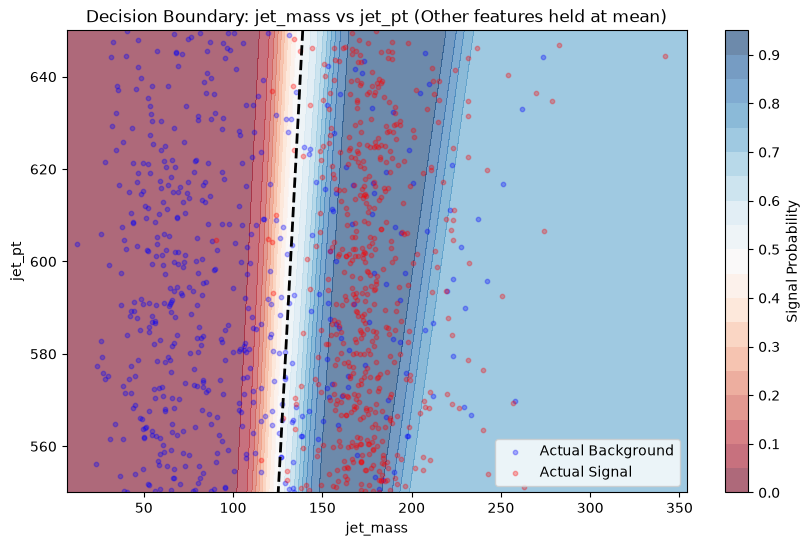

In [21]:
import matplotlib.pyplot as plt

def plot_physics_decision_boundary(model, X_df, feature_x='jet_mass', feature_y='jet_pt'):
    # Set model to eval mode
    model.eval()
    
    # Create a baseline row filled with the mean values of all 10 features
    mean_values = X_df.mean().values
    feature_indices = {col: i for i, col in enumerate(X_df.columns)}
    
    idx_x = feature_indices[feature_x]
    idx_y = feature_indices[feature_y]
    
    # Create a grid mesh based on the range of your validation data
    x_min, x_max = X_df[feature_x].min(), X_df[feature_x].max()
    y_min, y_max = X_df[feature_y].min(), X_df[feature_y].max()
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
    
    # Flatten the grid coordinates
    grid_points = xx.ravel()
    num_points = len(grid_points)
    
    # Construct a synthetic input matrix (N_points, 10) holding means everywhere
    # except for the two target features we are sweeping across the grid
    synthetic_inputs = np.tile(mean_values, (num_points, 1))
    synthetic_inputs[:, idx_x] = xx.ravel()
    synthetic_inputs[:, idx_y] = yy.ravel()
    
    # Convert synthetic grid to PyTorch tensor and get probabilities
    grid_tensor = torch.tensor(synthetic_inputs, dtype=torch.float32)
    with torch.no_grad():
        grid_probs = model(grid_tensor).numpy().reshape(xx.shape)
        
    # Plot the background color scale matching the model's confidence boundary
    plt.figure(figsize=(10, 6))
    contour = plt.contourf(xx, yy, grid_probs, levels=20, cmap='RdBu', alpha=0.6)
    cbar = plt.colorbar(contour)
    cbar.set_label('Signal Probability')
    
    # Draw the specific 0.5 decision threshold line
    plt.contour(xx, yy, grid_probs, levels=[0.5], colors='black', linewidths=2, linestyles='dashed')
    
    # Overlay a small subset sample of actual validation points for comparison
    sample_df = X_df.copy()
    sample_df['label'] = y_val.values
    sample_bg = sample_df[sample_df['label'] == 0].sample(500, random_state=42)
    sample_sig = sample_df[sample_df['label'] == 1].sample(500, random_state=42)
    
    plt.scatter(sample_bg[feature_x], sample_bg[feature_y], color='blue', alpha=0.3, label='Actual Background', s=10)
    plt.scatter(sample_sig[feature_x], sample_sig[feature_y], color='red', alpha=0.3, label='Actual Signal', s=10)
    
    plt.xlabel(feature_x)
    plt.ylabel(feature_y)
    plt.title(f'Decision Boundary: {feature_x} vs {feature_y} (Other features held at mean)')
    plt.legend()
    plt.show()

# Execute the visualization function
plot_physics_decision_boundary(model, X_val, feature_x='jet_mass', feature_y='jet_pt')


In [22]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve
)

def evaluate_nn(model, X_tensor, y_true, split_name="Validation"):
    model.eval()

    with torch.no_grad():
        probabilities = model(X_tensor).cpu().numpy().ravel()

    y_true = np.asarray(y_true).ravel().astype(int)
    predictions = (probabilities >= 0.5).astype(int)

    metrics = {
        "Split": split_name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision (Signal)": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall (Signal)": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1 (Signal)": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "Average Precision": average_precision_score(
            y_true, probabilities
        ),
        "Log Loss": log_loss(
            y_true, np.clip(probabilities, 1e-7, 1 - 1e-7)
        )
    }

    print(f"\n{'=' * 20} {split_name} {'=' * 20}")
    print(pd.Series(metrics).to_string())
    print("\nClassification report:")
    print(classification_report(
        y_true,
        predictions,
        target_names=["QCD Background (0)", "Top Signal (1)"],
        digits=4,
        zero_division=0
    ))

    cm = confusion_matrix(y_true, predictions, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    print("Confusion matrix:")
    print(cm)
    print(f"TN={tn:,} | FP={fp:,} | FN={fn:,} | TP={tp:,}")
    print(f"Background rejection = {tn / (tn + fp):.4f}")
    print(f"Signal efficiency    = {tp / (tp + fn):.4f}")

    return {
        "metrics": metrics,
        "y_true": y_true,
        "probabilities": probabilities,
        "predictions": predictions,
        "confusion_matrix": cm
    }

In [23]:
val_results = evaluate_nn(
    model=model,
    X_tensor=X_val_tensor,
    y_true=y_val,
    split_name="Validation"
)


==================== Validation ====================
Split                 Validation
Accuracy                 0.89579
Precision (Signal)        0.8449
Recall (Signal)         0.970532
F1 (Signal)             0.903369
ROC-AUC                 0.947946
Average Precision       0.924852
Log Loss                0.263087

Classification report:
                    precision    recall  f1-score   support

QCD Background (0)     0.9651    0.8205    0.8869     49810
    Top Signal (1)     0.8449    0.9705    0.9034     50190

          accuracy                         0.8958    100000
         macro avg     0.9050    0.8955    0.8951    100000
      weighted avg     0.9048    0.8958    0.8952    100000

Confusion matrix:
[[40868  8942]
 [ 1479 48711]]
TN=40,868 | FP=8,942 | FN=1,479 | TP=48,711
Background rejection = 0.8205
Signal efficiency    = 0.9705


In [24]:
# Test set: pehle file mein available events ki tadaad check karo.
with tables.open_file("test.h5", mode="r") as h5:
    print("Available test events:", h5.root.table.table.nrows)

Available test events: 404000


In [25]:
# Pehle 100,000 test events se start karo.
X_test, y_test = calculate_physics_features(
    "test.h5",
    N=100_000,
    chunk_size=5_000
)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)
print("Feature order matches:", list(X_test.columns) == list(X_val.columns))
print(y_test.value_counts())

assert list(X_test.columns) == list(X_val.columns)
assert X_test.shape[1] == 10

X_test_tensor = torch.tensor(
    X_test.to_numpy(dtype=np.float32),
    dtype=torch.float32
)

test_results = evaluate_nn(
    model=model,
    X_tensor=X_test_tensor,
    y_true=y_test,
    split_name="Test"
)

X_test: (100000, 10)
y_test: (100000,)
Feature order matches: True
is_signal_new
0    50570
1    49430
Name: count, dtype: int64

==================== Test ====================
Split                     Test
Accuracy               0.89525
Precision (Signal)     0.84051
Recall (Signal)       0.972648
F1 (Signal)           0.901764
ROC-AUC               0.948907
Average Precision     0.923363
Log Loss                0.2621

Classification report:
                    precision    recall  f1-score   support

QCD Background (0)     0.9684    0.8196    0.8878     50570
    Top Signal (1)     0.8405    0.9726    0.9018     49430

          accuracy                         0.8952    100000
         macro avg     0.9045    0.8961    0.8948    100000
      weighted avg     0.9052    0.8952    0.8947    100000

Confusion matrix:
[[41447  9123]
 [ 1352 48078]]
TN=41,447 | FP=9,123 | FN=1,352 | TP=48,078
Background rejection = 0.8196
Signal efficiency    = 0.9726


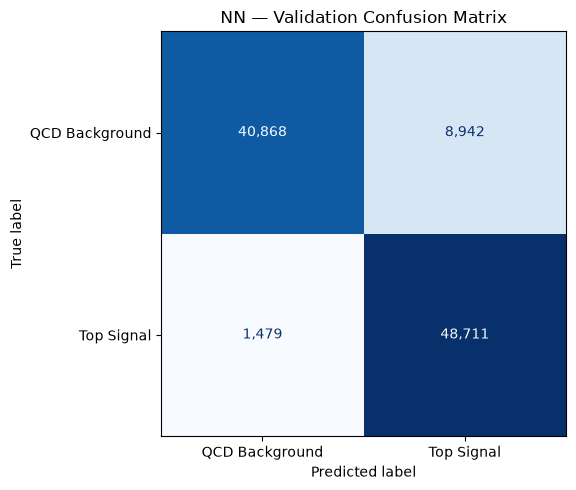

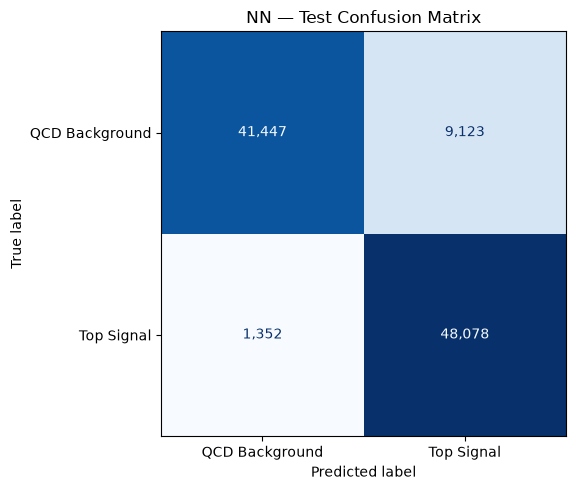

In [26]:
def plot_confusion_matrix_results(results, title):
    cm = results["confusion_matrix"]

    fig, ax = plt.subplots(figsize=(6, 5))
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["QCD Background", "Top Signal"]
    )
    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format=",",
        colorbar=False
    )
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


plot_confusion_matrix_results(
    val_results, "NN — Validation Confusion Matrix"
)

plot_confusion_matrix_results(
    test_results, "NN — Test Confusion Matrix"
)

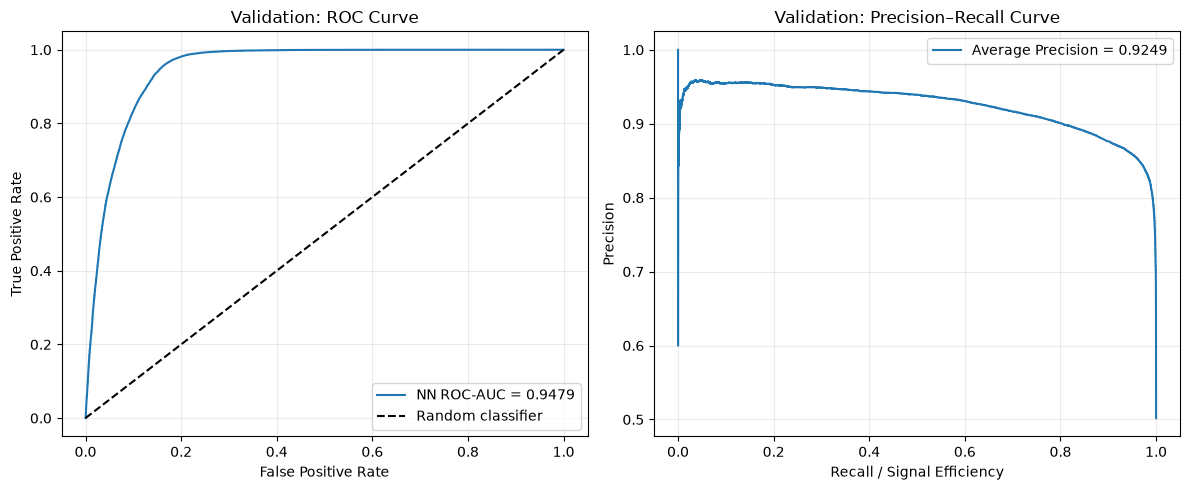

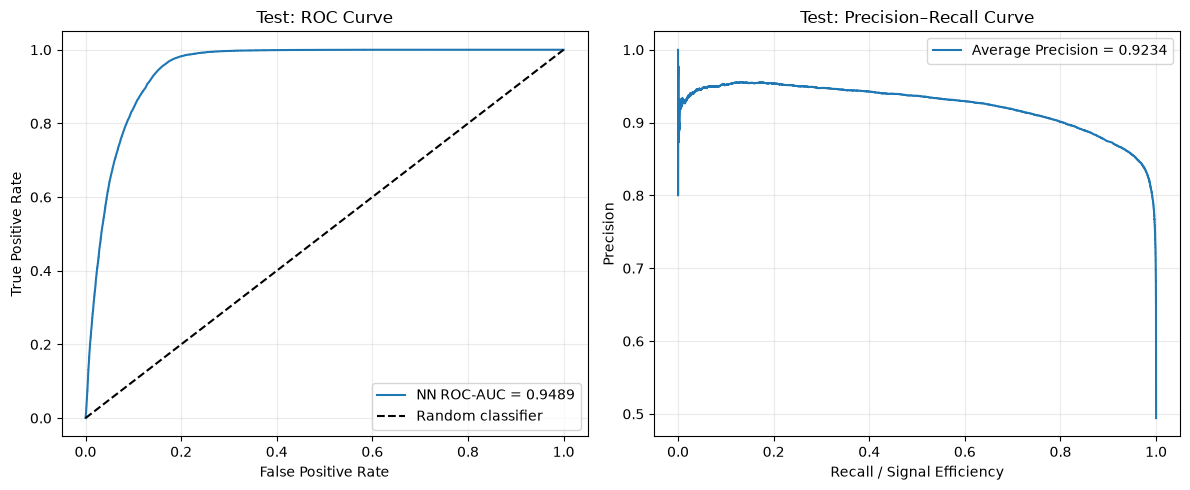

In [27]:
def plot_roc_pr(results, split_name):
    y = results["y_true"]
    probs = results["probabilities"]

    fpr, tpr, _ = roc_curve(y, probs)
    auc = roc_auc_score(y, probs)

    precision, recall, _ = precision_recall_curve(y, probs)
    ap = average_precision_score(y, probs)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].plot(fpr, tpr, label=f"NN ROC-AUC = {auc:.4f}")
    axes[0].plot([0, 1], [0, 1], "k--", label="Random classifier")
    axes[0].set(
        xlabel="False Positive Rate",
        ylabel="True Positive Rate",
        title=f"{split_name}: ROC Curve"
    )
    axes[0].legend()
    axes[0].grid(alpha=0.25)

    axes[1].plot(recall, precision, label=f"Average Precision = {ap:.4f}")
    axes[1].set(
        xlabel="Recall / Signal Efficiency",
        ylabel="Precision",
        title=f"{split_name}: Precision–Recall Curve"
    )
    axes[1].legend()
    axes[1].grid(alpha=0.25)

    plt.tight_layout()
    plt.show()


plot_roc_pr(val_results, "Validation")
plot_roc_pr(test_results, "Test")

In [28]:
def plot_nn_decision_boundary(
    model,
    X_df,
    y_labels,
    feature_x="jet_mass",
    feature_y="jet_pt",
    grid_size=200,
    sample_size=500
):
    model.eval()

    feature_names = list(X_df.columns)
    idx_x = feature_names.index(feature_x)
    idx_y = feature_names.index(feature_y)

    # Hold remaining features at their validation means.
    baseline = X_df.mean().to_numpy(dtype=np.float32)

    x_min, x_max = X_df[feature_x].quantile([0.01, 0.99])
    y_min, y_max = X_df[feature_y].quantile([0.01, 0.99])

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, grid_size),
        np.linspace(y_min, y_max, grid_size)
    )

    grid = np.tile(baseline, (xx.size, 1))
    grid[:, idx_x] = xx.ravel()
    grid[:, idx_y] = yy.ravel()

    grid_tensor = torch.tensor(grid, dtype=torch.float32)

    with torch.no_grad():
        probs = model(grid_tensor).cpu().numpy().ravel()
    probs = probs.reshape(xx.shape)

    fig, ax = plt.subplots(figsize=(9, 6))

    filled = ax.contourf(
        xx, yy, probs,
        levels=np.linspace(0, 1, 21),
        cmap="RdBu_r",
        alpha=0.65
    )
    fig.colorbar(filled, ax=ax, label="Predicted top-signal probability")

    # The model's 0.5 probability contour, if it crosses this slice.
    if probs.min() <= 0.5 <= probs.max():
        ax.contour(
            xx, yy, probs,
            levels=[0.5],
            colors="black",
            linewidths=2
        )

    plot_df = X_df.copy()
    plot_df["label"] = np.asarray(y_labels).ravel()

    for label, color, name in [
        (0, "blue", "QCD Background"),
        (1, "red", "Top Signal")
    ]:
        subset = plot_df[plot_df["label"] == label]
        n = min(sample_size, len(subset))
        subset = subset.sample(n=n, random_state=42)

        ax.scatter(
            subset[feature_x],
            subset[feature_y],
            c=color,
            alpha=0.25,
            s=10,
            label=name
        )

    ax.set_xlabel(feature_x)
    ax.set_ylabel(feature_y)
    ax.set_title(
        f"NN decision-boundary slice: {feature_x} vs {feature_y}\n"
        "Other 8 features held at their means"
    )
    ax.legend()
    plt.tight_layout()
    plt.show()

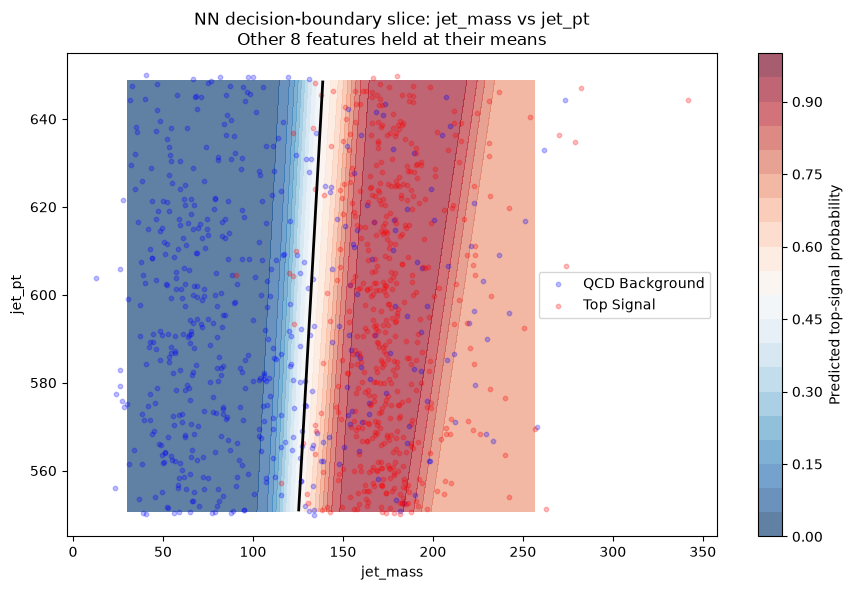

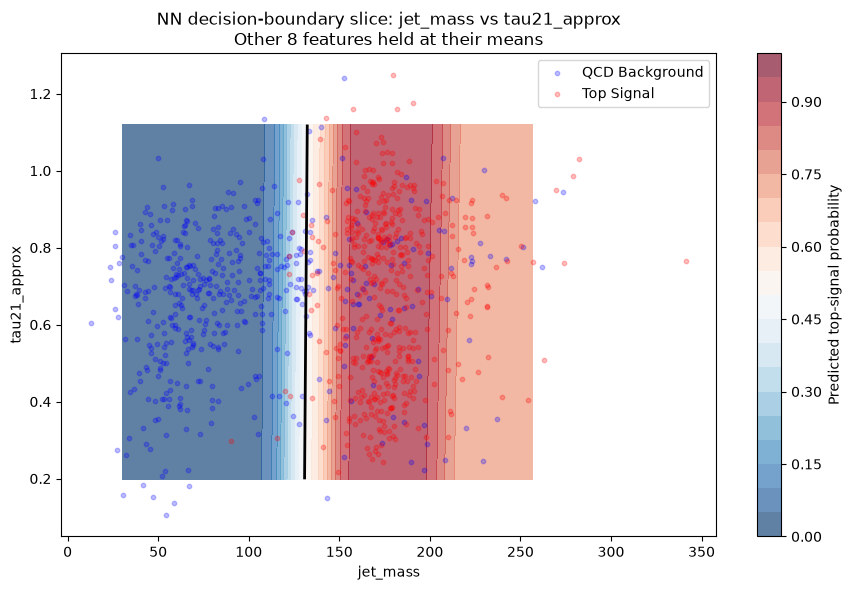

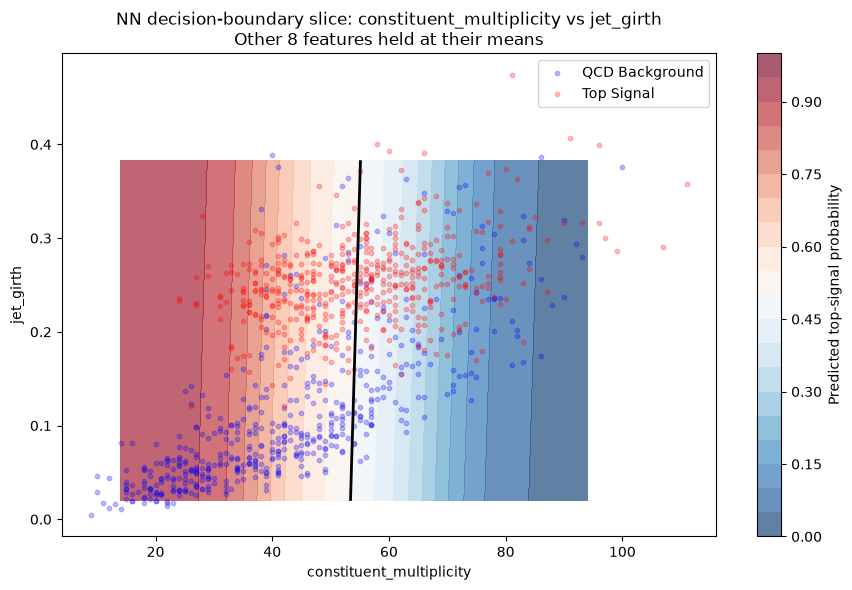

In [29]:
plot_nn_decision_boundary(
    model, X_val, y_val,
    feature_x="jet_mass",
    feature_y="jet_pt"
)

plot_nn_decision_boundary(
    model, X_val, y_val,
    feature_x="jet_mass",
    feature_y="tau21_approx"
)

plot_nn_decision_boundary(
    model, X_val, y_val,
    feature_x="constituent_multiplicity",
    feature_y="jet_girth"
)

In [30]:
import joblib

# Load the model back into memory
clf_bdt = joblib.load('clf_bdt_model.pkl')

# Now you can use it immediately
# predictions = clf_bdt.predict(X_test)


In [31]:
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score

# NN probabilities from the test evaluation above
nn_probs = test_results["probabilities"]
nn_preds = test_results["predictions"]

# Existing BDT: use exactly the same test feature matrix
bdt_probs = clf_bdt.predict_proba(X_test)[:, 1]
bdt_preds = clf_bdt.predict(X_test)

comparison = pd.DataFrame({
    "Model": ["BDT", "Neural Network"],
    "Accuracy": [
        accuracy_score(y_test, bdt_preds),
        accuracy_score(y_test, nn_preds)
    ],
    "F1 (Signal)": [
        f1_score(y_test, bdt_preds),
        f1_score(y_test, nn_preds)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, bdt_probs),
        roc_auc_score(y_test, nn_probs)
    ]
})

display(comparison.round(4))

,Model,Accuracy,F1 (Signal),ROC-AUC
0,BDT,0.9081,0.9108,0.9663
1,Neural Network,0.8952,0.9018,0.9489
